# Eksploracja danych · Laboratorium 8
## Regresja: ile wyda klient, który zostaje?

**Sytuacja.** W laboratorium 7 drzewo wskazywało, kto odejdzie, a o kuponie decydowaliśmy przy założeniu, że każdy zatrzymany klient to **250 zł** marży. To uproszczenie: klient, który wydaje 300 zł rocznie, jest wart mniej niż ten, który wydaje 6000 zł. Dziś przewidujemy **liczbę**, a nie klasę: ile klient wyda w kolejnym półroczu. To jest **regresja**.

**Dane:** `klienci_wartosc.csv`: ci sami 1206 klienci co w laboratoriach 3 i 7, z nową kolumną:

| Kolumna | Opis |
|---|---|
| `wydatki_6m` | wartość zamówień od 01.10.2026 do 31.03.2027 [zł]; **0** dla klientów, którzy odeszli |
| pozostałe | jak w laboratorium 7 (stan na 30.09.2026), `odszedl` = 1: brak zamówień w tym półroczu |

**Zasada pracy:** luki `___` z komentarzem `UZUPEŁNIJ`. Decyzje i odpowiedzi zapisujemy w komórkach tekstowych. Przed oddaniem: *Kernel → Restart Kernel and Run All Cells*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import sklearn
print("scikit-learn", sklearn.__version__)
pd.set_option("display.precision", 3)

scikit-learn 1.9.1


## Z1. Rozgrzewka: prosta na kartce

Pięciu klientów: wydatki w ostatnim roku (x) i w kolejnym półroczu (y). Szukamy prostej **y = a + b·x**, dla której suma kwadratów błędów jest najmniejsza (metoda najmniejszych kwadratów). Wzory:

$$b = \frac{\sum (x - \bar x)(y - \bar y)}{\sum (x - \bar x)^2}, \qquad a = \bar y - b \, \bar x$$

Na kartce: policz średnie, odchylenia, b, a, prognozy, błędy (y − prognoza) i **średni błąd bezwzględny** (MAE: średnia z wartości bezwzględnych błędów). Potem sprawdź kodem.

In [2]:
t = pd.read_csv("pieciu_klientow.csv", sep=";")
t

,klient,wydatki_rok,wydatki_6m
0,A,400,300
1,B,800,300
2,C,1200,700
3,D,1600,700
4,E,2000,1000


In [3]:
x, y = t["wydatki_rok"], t["wydatki_6m"]
dx, dy = x - x.mean(), y - y.mean()
b = (dx * dy).sum() / (dx ** 2).sum()      # UZUPEŁNIJ: potęga w mianowniku
a = y.mean() - b * x.mean()
prognoza = a + b * x
print(f"b = {b:.3f}   a = {a:.1f}")
print("prognozy:", prognoza.tolist())
print("błędy:   ", (y - prognoza).tolist())
print("MAE:", (y - prognoza).abs().mean())

b = 0.450   a = 60.0
prognozy: [240.0, 420.0, 600.0, 780.0, 960.0]
błędy:    [60.0, -120.0, 100.0, -80.0, 40.0]
MAE: 80.0


**Pytanie:** co oznacza b w złotówkach? Ile według prostej wyda w półroczu klient, który w roku wydał 1000 zł?

*Odpowiedź:* x̄ = 1200, ȳ = 600, Σ(x − x̄)(y − ȳ) = 720 000, Σ(x − x̄)² = 1 600 000, więc **b = 0,45**, **a = 600 − 0,45 · 1200 = 60**. Prognozy: 240, 420, 600, 780, 960; błędy: 60, −120, 100, −80, 40; **MAE = 400 / 5 = 80 zł** (zgadza się z kodem).
**b = 0,45** znaczy: każda złotówka wydana w ostatnim roku to średnio **45 groszy** wydatków w kolejnym półroczu. Klient, który w roku wydał 1000 zł, według prostej wyda w półroczu **60 + 0,45 · 1000 = 510 zł**.

## Z2. Dane: kogo modelujemy?

Klient, który odszedł, ma `wydatki_6m = 0`. To inny proces (odejście) niż „ile wyda, jeśli zostanie”, a odejście przewidywaliśmy już w lab. 7. Regresję uczymy więc tylko na klientach, którzy **zostali**.

In [4]:
df = pd.read_csv("klienci_wartosc.csv", sep=";", decimal=",")
zostali = df[df["odszedl"] == 0].copy()        # UZUPEŁNIJ: klienci, którzy zostali
print("wszystkich:", len(df), " zostało:", len(zostali))
zostali["wydatki_6m"].describe()

wszystkich: 1206  zostało: 825


count      825.000
mean      1156.022
std       2419.208
min         58.520
25%        253.770
50%        570.570
75%       1293.070
max      40355.480
Name: wydatki_6m, dtype: float64

In [5]:
# konta firmowe znane z laboratorium 3: wydatki powyżej 20 000 zł rocznie
zostali[zostali["wydatki_zl"] > 20000][["nr_karty", "liczba_zamowien", "wydatki_zl", "wydatki_6m"]]

,nr_karty,liczba_zamowien,wydatki_zl,wydatki_6m
82,101152,74,74343.21,37497.27
204,101106,51,52104.29,2140.00
1107,101143,52,61583.28,40355.48
1138,101134,46,38419.94,23210.99


korelacja (bez firm): 0.797


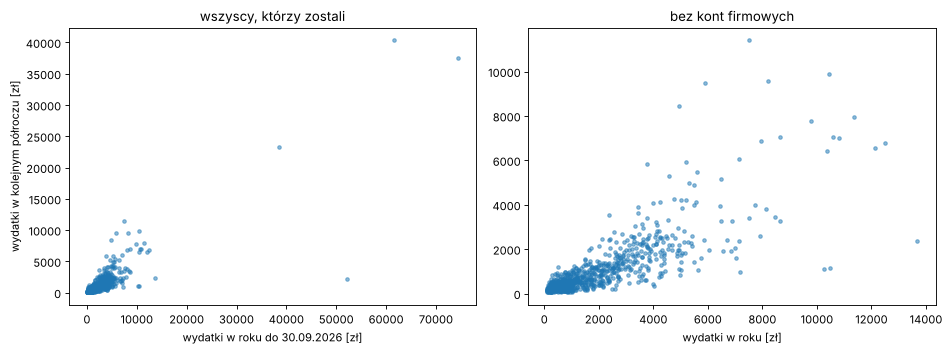

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(zostali["wydatki_zl"], zostali["wydatki_6m"], s=10, alpha=.5)
ax[0].set_xlabel("wydatki w roku do 30.09.2026 [zł]"); ax[0].set_ylabel("wydatki w kolejnym półroczu [zł]"); ax[0].set_title("wszyscy, którzy zostali")
ind = zostali[zostali["wydatki_zl"] <= 20000]
ax[1].scatter(ind["wydatki_zl"], ind["wydatki_6m"], s=10, alpha=.5)
ax[1].set_xlabel("wydatki w roku [zł]"); ax[1].set_title("bez kont firmowych")
plt.tight_layout(); plt.show()
print("korelacja (bez firm):", round(ind["wydatki_zl"].corr(ind["wydatki_6m"]), 3))

**Zapisz:** ilu klientów modelujemy? Czym różnią się konta firmowe? Jak wygląda zależność na wykresie po prawej?

*Odpowiedź:* Z 1206 klientów **zostało 825**: tylko ich modelujemy, bo odejście (wydatki = 0) to inny proces, przewidywany w lab. 7. Mediana wydatków w półroczu to 571 zł, średnia 1156 zł, maksimum 40 355 zł. **4 konta firmowe** (101152, 101106, 101143, 101134) mają 38–74 tys. zł wydatków i 46–74 zamówienia w roku, kilkanaście razy więcej niż zwykły klient, i zachowują się nieprzewidywalnie: 101106 wydało 52 tys. zł w roku, a w półroczu tylko 2140 zł. Na wykresie po prawej, bez firm, widać wyraźną **dodatnią, prawie liniową zależność** (korelacja **0,797**): kto więcej wydał w roku, wyda więcej w półroczu. Rozrzut punktów rośnie jednak razem z wydatkami (kształt lejka).

**Z3:** konta firmowe przekrzywiają prostą: **nachylenie 0,476 z firmami, 0,530 bez nich** (wyraz wolny 112,4 vs 16,1). To obserwacje wpływowe: leżą daleko na osi x, więc „ciągną” prostą (szczególnie 101106). Dalej modelujemy **821 klientów indywidualnych**.

## Z3. Jedna firma potrafi przekrzywić prostą

Porównaj prostą dopasowaną do wszystkich, którzy zostali, z prostą bez kont firmowych. Spójrz na konto 101106: w roku wydało ponad 52 tys. zł, w półroczu tylko 2140 zł (utracony kontrakt).

In [7]:
m_wsz = LinearRegression().fit(zostali[["wydatki_zl"]], zostali["wydatki_6m"])
m_ind = LinearRegression().fit(ind[["wydatki_zl"]], ind["wydatki_6m"])
print(f"z firmami:  wydatki_6m = {m_wsz.intercept_:7.1f} + {m_wsz.coef_[0]:.3f} × wydatki_rok")
print(f"bez firm:   wydatki_6m = {m_ind.intercept_:7.1f} + {m_ind.coef_[0]:.3f} × wydatki_rok")

z firmami:  wydatki_6m =   112.4 + 0.476 × wydatki_rok
bez firm:   wydatki_6m =    16.1 + 0.530 × wydatki_rok


**Decyzja:** dalej modelujemy **klientów indywidualnych** (bez 4 kont firmowych). Konta firmowe obsługuje handlowiec, a 4 obserwacje to za mało, żeby się czegoś o nich nauczyć.

## Z4. Zbiory i punkt odniesienia

Jak w lab. 7: 30% klientów odkładamy na test. Najprostsza prognoza dla każdego: **średnia** wydatków ze zbioru uczącego. Mierzymy trzy błędy:
* **MAE**: średni błąd bezwzględny w zł („mylimy się średnio o … zł”),
* **RMSE**: pierwiastek ze średniego kwadratu błędu; mocniej karze duże pomyłki,
* **R²**: jaka część zmienności wydatków jest wyjaśniona (1 = idealnie, 0 = nie lepiej niż średnia).

In [8]:
CECHY = ["liczba_zamowien", "wydatki_zl", "sredni_koszyk_zl", "dni_od_ostatniego",
         "udzial_promocji", "udzial_internet", "liczba_kategorii", "zwroty"]
ucz, test = train_test_split(ind, test_size=0.3, random_state=42)
y_test = test["wydatki_6m"]
print("uczący:", len(ucz), " testowy:", len(test))

def ocena(nazwa, prognoza):
    return {"model": nazwa, "MAE_zl": mean_absolute_error(y_test, prognoza),
            "RMSE_zl": mean_squared_error(y_test, prognoza) ** 0.5, "R2": r2_score(y_test, prognoza)}

wyniki = [ocena("średnia ze zbioru uczącego", np.full(len(test), ucz["wydatki_6m"].mean()))]
pd.DataFrame(wyniki)

uczący: 574  testowy: 247


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029


## Z5. Regresja prosta: wydatki w roku → wydatki w półroczu

In [9]:
prosta = LinearRegression().fit(ucz[["wydatki_zl"]], ucz["wydatki_6m"])      # UZUPEŁNIJ: jedna cecha
print(f"wydatki_6m = {prosta.intercept_:.1f} + {prosta.coef_[0]:.3f} × wydatki_zl")
p_prosta = prosta.predict(test[["wydatki_zl"]])
wyniki.append(ocena("regresja prosta (wydatki_zl)", p_prosta))
pd.DataFrame(wyniki)

wydatki_6m = 27.4 + 0.522 × wydatki_zl


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681


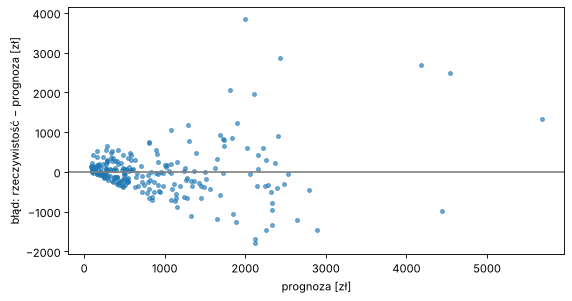

In [10]:
# wykres błędów: czy model myli się tak samo dla małych i dużych klientów?
plt.figure(figsize=(8, 4))
plt.scatter(p_prosta, y_test - p_prosta, s=12, alpha=.6)
plt.axhline(0, c="grey")
plt.xlabel("prognoza [zł]"); plt.ylabel("błąd: rzeczywistość − prognoza [zł]")
plt.show()

**Pytanie:** jak interpretujesz współczynnik? O ile model jest lepszy od średniej (MAE)? Co widać na wykresie błędów, gdy prognoza rośnie?

*Odpowiedź:* Model: **wydatki_6m = 27,4 + 0,522 × wydatki_zl**. Każda złotówka wydana w roku podnosi prognozę na półrocze średnio o **52 grosze** (1000 zł w roku → ok. 550 zł w półroczu). **MAE spada z 799,6 zł (średnia) do 375,1 zł**, czyli o ok. 424 zł (53%), a **R² = 0,681**: model wyjaśnia ok. dwóch trzecich zmienności wydatków (średnia: R² ≈ 0).
Na wykresie błędów widać **lejek**: im większa prognoza, tym większy rozrzut błędów. U małych klientów pomyłki to ok. 130 zł, u największych ok. 840 zł (średni |błąd| w najniższej i najwyższej ćwiartce prognoz). Model myli się „procentowo”, a nie o stałą kwotę, co jest powodem do użycia logarytmu (Z7).

## Z6. Regresja wieloraka: wszystkie cechy naraz

Każda cecha dostaje własny współczynnik: o ile złotych zmienia się prognoza, gdy cecha rośnie o 1, **a pozostałe się nie zmieniają**.

In [11]:
wiel = LinearRegression().fit(ucz[CECHY], ucz["wydatki_6m"])
print(pd.Series(wiel.coef_, index=CECHY).round(3))
wyniki.append(ocena("regresja wieloraka (8 cech)", wiel.predict(test[CECHY])))
pd.DataFrame(wyniki)

liczba_zamowien       8.495
wydatki_zl            0.309
sredni_koszyk_zl      1.814
dni_od_ostatniego    -1.894
udzial_promocji     -13.100
udzial_internet      18.204
liczba_kategorii      1.311
zwroty              -82.567
dtype: float64


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681
2,regresja wieloraka (8 cech),363.096,596.993,0.708


In [12]:
# cechy powiązane ze sobą: wydatki = liczba zamówień × średni koszyk
ind[["liczba_zamowien", "wydatki_zl", "sredni_koszyk_zl"]].corr().round(2)

,liczba_zamowien,wydatki_zl,sredni_koszyk_zl
liczba_zamowien,1.00,0.54,0.00
wydatki_zl,0.54,1.00,0.78
sredni_koszyk_zl,0.00,0.78,1.00


**Pytanie:** jaki znak ma współczynnik przy `dni_od_ostatniego` i co znaczy w złotówkach? Dlaczego współczynnik przy `wydatki_zl` spadł w porównaniu z regresją prostą? Czy można z niego wnioskować „podnieśmy klientowi wydatki o 1 zł”?

*Odpowiedź:* Współczynnik przy `dni_od_ostatniego` jest **ujemny: −1,894**. Każdy dzień bez zamówienia, **przy pozostałych cechach bez zmian**, obniża prognozę o ok. **1,89 zł** (100 dni → ok. −189 zł). Regresja wieloraka ma MAE 363,1 zł i R² 0,708.
Współczynnik przy `wydatki_zl` spadł z **0,522 do 0,309**, bo wydatki są silnie powiązane z innymi cechami: z koszykiem (korelacja 0,78) i liczbą zamówień (0,54), a wydatki ≈ liczba zamówień × średni koszyk. Część „efektu wydatków” przejęły teraz `sredni_koszyk_zl` (1,814 zł na 1 zł koszyka) i `liczba_zamowien` (8,5 zł na zamówienie).
**Nie można** wnioskować „podnieśmy klientowi wydatki o 1 zł, to wyda o 31 gr więcej”. Współczynnik opisuje zależność w danych (korelację), a nie przyczynę. Poza tym nie da się zmienić wydatków przy stałej liczbie zamówień i stałym koszyku, bo wydatki są ich iloczynem.

## Z7. Logarytm: procenty zamiast złotówek

Pieniądze są skośne: kilku dużych klientów, wielu małych, a błąd rośnie z wielkością klienta (Z5). Po zlogarytmowaniu kwot współczynnik czytamy w **procentach**: wzrost wydatków w roku o 1% → wzrost prognozy o b%. Prognozę wracamy do złotówek funkcją `np.exp`.

In [13]:
def cechy_log(d):
    return pd.DataFrame({"log_wydatki": np.log(d["wydatki_zl"]), "log_koszyk": np.log(d["sredni_koszyk_zl"]),
                         "dni_od_ostatniego": d["dni_od_ostatniego"]})

logm = LinearRegression().fit(cechy_log(ucz), np.log(ucz["wydatki_6m"]))
print(pd.Series(logm.coef_, index=["log_wydatki", "log_koszyk", "dni_od_ostatniego"]).round(4))
p_log = np.exp(logm.predict(cechy_log(test)))          # UZUPEŁNIJ: z logarytmu z powrotem do złotówek
wyniki.append(ocena("log: wydatki, koszyk, dni", p_log))
pd.DataFrame(wyniki)

log_wydatki          0.516
log_koszyk           0.488
dni_od_ostatniego   -0.003
dtype: float64


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681
2,regresja wieloraka (8 cech),363.096,596.993,0.708
3,"log: wydatki, koszyk, dni",342.348,602.828,0.702


**Pytanie:** jak czytasz współczynnik przy `log_wydatki`? A przy `dni_od_ostatniego` (wskazówka: −0,003 na dzień ≈ −0,3% na dzień)? Który model ma najmniejszy MAE?

*Odpowiedź:* `log_wydatki` = **0,516**: wzrost wydatków w roku o **1%** daje wzrost prognozy o ok. **0,52%** (przy tym samym koszyku i dniach). Podobnie `log_koszyk` = 0,488: koszyk +1% → prognoza +0,49%. `dni_od_ostatniego` = **−0,0031**: każdy dzień bez zamówienia obniża prognozę o ok. **0,3%**; 100 dni → ok. **−26%** (e^(−0,31) ≈ 0,74).
**Najmniejszy MAE ma model na logarytmach: 342,3 zł** (prosta 375,1 zł, wieloraka 363,1 zł, średnia 799,6 zł). R² (0,702) i RMSE ma nieco gorsze niż wieloraka, bo model logarytmiczny pilnuje błędów procentowych, a nie największych pomyłek w złotówkach.

## Z8. A może drzewo? Drzewo regresyjne z lab. 7

Drzewo regresyjne działa jak klasyfikacyjne, tylko w liściu podaje **średnią** wydatków klientów z tego liścia.

In [14]:
for g in [2, 3, 4, 6]:
    drz = DecisionTreeRegressor(max_depth=g, min_samples_leaf=20, random_state=0).fit(ucz[CECHY], ucz["wydatki_6m"])   # UZUPEŁNIJ: jak w lab. 7
    wyniki.append(ocena(f"drzewo regresyjne, głębokość {g}", drz.predict(test[CECHY])))
tabela = pd.DataFrame(wyniki).round({"MAE_zl": 1, "RMSE_zl": 1, "R2": 3})
tabela

,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.6,1120.3,-0.029
1,regresja prosta (wydatki_zl),375.1,623.3,0.681
2,regresja wieloraka (8 cech),363.1,597.0,0.708
3,"log: wydatki, koszyk, dni",342.3,602.8,0.702
4,"drzewo regresyjne, głębokość 2",462.0,741.8,0.549
5,"drzewo regresyjne, głębokość 3",398.7,669.6,0.632
6,"drzewo regresyjne, głębokość 4",394.1,674.2,0.627
7,"drzewo regresyjne, głębokość 6",387.9,672.2,0.629


**Pytanie:** dlaczego drzewo przegrywa tu z regresją liniową? (Wskazówka: ile różnych prognoz daje drzewo o głębokości 3, a ile prosta?)

*Odpowiedź:* Drzewo regresyjne o głębokości 3 ma **MAE 398,7 zł**, gorzej niż model logarytmiczny (342,3 zł) i nawet regresja prosta (375,1 zł). Głębsze drzewa niewiele pomagają (gł. 6: 387,9 zł). Drzewo o głębokości 3 daje **najwyżej 8 różnych prognoz** (średnie liści, tu 7 wartości od ok. 313 do 5144 zł), czyli „schodki”: wszyscy klienci w liściu dostają tę samą kwotę. Prosta daje **inną prognozę dla każdego klienta**, a zależność „więcej wydał w roku → więcej wyda w półroczu” jest **gładka i prawie liniowa**, więc prosta pasuje do niej lepiej. Drzewo jest dobre, gdy zależność jest progowa (jak w lab. 7: powyżej 175 dni ryzyko skacze).

## Z9. Decyzja o kuponie z wartością klienta

Łączymy dwa modele: **ryzyko** odejścia z drzewa z lab. 7 i **wartość** klienta z modelu logarytmicznego (Z7). Marża to 25% wydatków, a zatrzymany klient zostaje z nami co najmniej rok, czyli dwa półrocza. Oczekiwany zysk z kuponu:

**zysk = ryzyko × 0,30 × 0,25 × 2 × prognozowane wydatki w półroczu − 30 zł**

Porównujemy z regułą z lab. 7 (kupon, gdy ryzyko ≥ 0,4: założenie, że każdy zatrzymany klient jest wart 250 zł).

In [15]:
# model ryzyka z lab. 7 (te same ustawienia)
CECHY7 = CECHY
Xu, Xt, yu, yt = train_test_split(df[CECHY7], df["odszedl"], test_size=0.3, stratify=df["odszedl"], random_state=42)
drzewo7 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xu, yu)

klienci = df[df["wydatki_zl"] <= 20000].copy()                     # klienci indywidualni
klienci["ryzyko"] = drzewo7.predict_proba(klienci[CECHY7])[:, 1]
klienci["wartosc_6m"] = np.exp(logm.predict(cechy_log(klienci)))   # ile wyda, jeśli zostanie
klienci["zysk_kuponu"] = klienci["ryzyko"] * 0.30 * 0.25 * 2 * klienci["wartosc_6m"] - 30   # UZUPEŁNIJ: marża 25%

stara = klienci["ryzyko"] >= 0.4
nowa = klienci["zysk_kuponu"] > 0
print("kuponów, reguła z lab. 7:", stara.sum(), "  nowa reguła:", nowa.sum())
print("w obu:", (stara & nowa).sum(), " tylko w starej:", (stara & ~nowa).sum(), " tylko w nowej:", (~stara & nowa).sum())

kuponów, reguła z lab. 7: 429   nowa reguła: 170
w obu: 125  tylko w starej: 304  tylko w nowej: 45


In [16]:
cols = ["nr_karty", "wydatki_zl", "dni_od_ostatniego", "ryzyko", "wartosc_6m", "zysk_kuponu"]
print("Przykłady: kupon w starej regule, nie w nowej (wysokie ryzyko, mała wartość)")
print(klienci[stara & ~nowa][cols].sort_values("zysk_kuponu").head(4).round(2).to_string(index=False))
print()
print("Przykłady: kupon tylko w nowej regule (umiarkowane ryzyko, duża wartość)")
print(klienci[~stara & nowa][cols].sort_values("zysk_kuponu", ascending=False).head(4).round(2).to_string(index=False))
print()
print(f"oczekiwany zysk (wg modeli): stara reguła {klienci.loc[stara, 'zysk_kuponu'].sum():.0f} zł, nowa {klienci.loc[nowa, 'zysk_kuponu'].sum():.0f} zł")
print(f"średnia roczna marża (wg modelu) klientów z kuponem w starej regule: {(0.25 * 2 * klienci.loc[stara, 'wartosc_6m']).mean():.0f} zł (założenie z lab. 7: 250 zł)")

Przykłady: kupon w starej regule, nie w nowej (wysokie ryzyko, mała wartość)
 nr_karty  wydatki_zl  dni_od_ostatniego  ryzyko  wartosc_6m  zysk_kuponu
   100948       60.12                234    0.86       45.52       -24.16
   100486       98.12                161    0.49       93.15       -23.10
   101116      109.28                162    0.49      103.48       -22.34
   101135       89.24                178    0.65       80.38       -22.16

Przykłady: kupon tylko w nowej regule (umiarkowane ryzyko, duża wartość)
 nr_karty  wydatki_zl  dni_od_ostatniego  ryzyko  wartosc_6m  zysk_kuponu
   100090     9770.87                 99    0.22     4432.10       113.74
   100786     6495.50                122    0.22     2954.65        65.83
   100450     5209.07                109    0.22     2463.36        49.89
   100685     5491.12                 96    0.22     2348.76        46.18

oczekiwany zysk (wg modeli): stara reguła -2017 zł, nowa 2326 zł
średnia roczna marża (wg modelu) klientów z

**Pytanie:** ile kuponów zmienia adresata? Jakich klientów nowa reguła pomija, a jakich dodaje? Ile naprawdę są warci klienci wysokiego ryzyka w porównaniu z założeniem 250 zł z lab. 7?

*Odpowiedź:* Reguła z lab. 7 daje **429 kuponów**, nowa **170**. W obu jest 125 klientów, więc **adresata zmienia 349 kuponów**: **304** kupony są tylko w starej regule (nowa je pomija), a **45** tylko w nowej (nowa je dodaje).
- **Nowa reguła pomija** klientów o **wysokim ryzyku, ale małej wartości**, np. karta 100948: 60 zł wydatków w roku, ryzyko 86%, prognoza 46 zł na półrocze, czyli oczekiwany zysk z kuponu −24 zł. Kupon 30 zł kosztuje więcej, niż taki klient jest wart.
- **Nowa reguła dodaje** klientów o **umiarkowanym lub niskim ryzyku, ale dużej wartości**, np. karta 100090: 9771 zł w roku, ryzyko tylko 22%, prognoza 4432 zł, czyli oczekiwany zysk +114 zł. Kupon dostaje nawet 32 bardzo dużych klientów z ryzykiem 6%.

Klienci wysokiego ryzyka są warci **dużo mniej**, niż zakładał lab. 7: średnia roczna marża (według modelu) klientów z kuponem w starej regule to **133 zł, nie 250 zł**. Dlatego oczekiwany zysk według modeli wynosi **−2017 zł dla starej reguły** i **+2326 zł dla nowej**. W decyzji liczy się **ryzyko × wartość**, a nie samo ryzyko.

## Zadanie domowe
**D1.** Zapisz model z Z7 jako zdanie dla działu marketingu: „klient, który wydał X zł, z koszykiem Y zł i ostatnim zamówieniem Z dni temu, wyda w półroczu ok. … zł”. Policz dla: 1500 zł, 150 zł, 30 dni oraz 1500 zł, 150 zł, 200 dni.

**D2.** W Z9 zmień skuteczność kuponu na 15%. Ilu klientów dostaje kupon według nowej reguły?

**D3.** (dla chętnych) Dodaj do `app.py` z laboratorium 7 pole „prognozowane wydatki w półroczu” i „oczekiwany zysk z kuponu”. Wzór na prognozę: współczynniki modelu z Z7 (wypisz `logm.intercept_` i `logm.coef_`). Wdróż na Render.

## Zadanie domowe: rozwiązanie

### D1. Model z Z7 jako zdanie dla marketingu

In [17]:
print("wyraz wolny:", round(float(logm.intercept_), 4), " współczynniki:", dict(zip(["log_wydatki", "log_koszyk", "dni_od_ostatniego"], [round(float(b), 5) for b in logm.coef_])))
d1 = pd.DataFrame({"wydatki_zl": [1500, 1500], "sredni_koszyk_zl": [150, 150], "dni_od_ostatniego": [30, 200]})
d1["prognoza_6m_zl"] = np.exp(logm.predict(cechy_log(d1))).round(0)
d1

wyraz wolny: 0.4205  współczynniki: {'log_wydatki': 0.51629, 'log_koszyk': 0.4884, 'dni_od_ostatniego': -0.00307}


,wydatki_zl,sredni_koszyk_zl,dni_od_ostatniego,prognoza_6m_zl
0,1500,150,30,700.0
1,1500,150,200,416.0


*Odpowiedź D1:* Model: **wydatki w półroczu ≈ exp(0,421 + 0,516 · ln(wydatki w roku) + 0,488 · ln(średni koszyk) − 0,00307 · dni od ostatniego zamówienia)**, czyli ≈ 1,52 · wydatki^0,516 · koszyk^0,488 · 0,9969^dni.

Dla marketingu: *„Im więcej klient wydał i im większy ma koszyk, tym więcej wyda: +1% wydatków w roku to +0,5% w półroczu. Każdy dzień bez zamówienia obniża prognozę o ok. 0,3% (100 dni ≈ −26%).”*
- Klient, który wydał **1500 zł**, z koszykiem **150 zł** i ostatnim zamówieniem **30 dni** temu, wyda w półroczu ok. **700 zł**.
- Ten sam klient z ostatnim zamówieniem **200 dni** temu wyda w półroczu ok. **416 zł**, czyli o ok. 41% mniej, bo 170 dni dłużej bez zamówienia daje e^(−0,00307·170) ≈ 0,59.

### D2. Skuteczność kuponu 15% zamiast 30%

In [18]:
klienci["zysk_kuponu_15"] = klienci["ryzyko"] * 0.15 * 0.25 * 2 * klienci["wartosc_6m"] - 30
nowa15 = klienci["zysk_kuponu_15"] > 0
print("kuponów, nowa reguła przy skuteczności 15%:", nowa15.sum(), "  (przy 30%:", nowa.sum(), ")")
print("w tym w starej regule (ryzyko >= 0,4):", (stara & nowa15).sum(), "  tylko w nowej:", (~stara & nowa15).sum())
print(f"oczekiwany zysk (wg modeli): {klienci.loc[nowa15, 'zysk_kuponu_15'].sum():.0f} zł")

kuponów, nowa reguła przy skuteczności 15%: 19   (przy 30%: 170 )
w tym w starej regule (ryzyko >= 0,4): 12   tylko w nowej: 7
oczekiwany zysk (wg modeli): 134 zł


*Odpowiedź D2:* Przy skuteczności 15% kupon według nowej reguły dostaje tylko **19 klientów** (przy 30%: 170). Oczekiwany zysk z kuponu spada o połowę, więc opłaca się on tylko przy dużej wartości klienta: przy ryzyku 86% klient musi mieć prognozę co najmniej ok. 467 zł na półrocze (30 / (0,856 · 0,15 · 0,25 · 2)), a przy ryzyku 22% aż ok. 1850 zł. 12 z tych 19 klientów ma też kupon w regule z lab. 7, a 7 to duzi klienci o niskim ryzyku. Oczekiwany zysk (według modeli) to ok. 134 zł.

### D3. (dla chętnych) Aplikacja
`app.py` rozbudowany: oprócz ryzyka z drzewa (lab. 7) pokazuje **prognozowane wydatki w półroczu** (model logarytmiczny z Z7, uczony w aplikacji na tych samych danych i z tym samym podziałem) oraz **oczekiwany zysk z kuponu** = ryzyko × 0,30 × 0,25 × 2 × prognoza − 30 zł, i decyzję według nowej reguły (kupon, gdy zysk > 0). Skuteczność kuponu można zmienić suwakiem (np. 15% z D2).

Sprawdzenie: klient z **1 zamówieniem (koszyk 200 zł) i 200 dniami** ma ryzyko 86%, prognozę **169 zł** i oczekiwany zysk z kuponu **−8,31 zł**: reguła z lab. 7 wysłałaby kupon, nowa nie. Klient z **10 zamówieniami po 500 zł i 99 dniami** ma ryzyko tylko 22%, ale prognozę **1899 zł** i zysk **+31,60 zł**, więc kupon dostaje tylko według nowej reguły.

Link do aplikacji na Render: `https://…onrender.com` *(wklej po wdrożeniu)*